# SCRUM-26: Time-Series Forecasting Model Implementation (Method 1)
### Final Review 2 Proof of Implementation & Verification Notebook
**Owner:** Mounik Sai (Reg: 23CSE01) · **Sprint:** Sprint 26 · **Target Presentation Slides:** Slides 9, 10, 11

---

### Notebook Purpose & Viva Defense Guide:
This notebook serves as the **verifiable empirical proof** for all Method 1 results presented in Review 2. It demonstrates:
1. **Chronological Train/Test Partitioning:** Strict 80/20 chronological boundary at August 12, 2026 (12,540 train rows, 3,180 held-out test rows across all 60 products) with zero lookahead leakage.
2. **10-Model Benchmark Comparison:** From simple baselines to statistical models (ARIMA, ETS) to lagged ML regressors (Ridge, ElasticNet, Random Forest, Gradient Boosting, LightGBM).
3. **Exact Metric Replication:** Tests MAE, RMSE, WAPE, $R^2$, and MDA matching the table on Slide 11.
4. **Visual Diagnostic Plots:** Embedded inline charts for model benchmarks, multi-cohort forecast trajectories, residual distributions, and feature importances.
5. **Artifact Verification:** Proof of generated files saved in `processed/` and `docs/figures/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

%matplotlib inline
plt.rcParams['figure.dpi'] = 150
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))

import config
import forecast_method1 as fm

paths = config.PATHS
print(f"Project root: {ROOT}")
print(f"Train split:  {paths.time_series_train_csv}")
print(f"Test split:   {paths.time_series_test_csv}")

Project root: /Users/mouniksai/Documents/viral-product-intelligence-
Train split:  /Users/mouniksai/Documents/viral-product-intelligence-/processed/train.csv
Test split:   /Users/mouniksai/Documents/viral-product-intelligence-/processed/test.csv


## Step 1: Chronological Train & Test Data Ingestion
We load the 80/20 chronological split. The training set covers January 15 to August 11, 2026 (209 days). The held-out test set covers August 12 to October 3, 2026 (53 days) across all 60 smartphone devices.

In [2]:
train_df = pd.read_csv(paths.time_series_train_csv)
test_df = pd.read_csv(paths.time_series_test_csv)

print(f"Train Partition: {train_df['date'].min()} to {train_df['date'].max()} ({len(train_df):,} rows, 60 products)")
print(f"Test Partition:  {test_df['date'].min()} to {test_df['date'].max()} ({len(test_df):,} rows, 60 products)")
print(f"Strict Temporal Split Cutoff: 2026-08-12 (Guarantees Zero Future Leakage)")

feature_cols = fm.get_method1_feature_columns(train_df)
print(f"Method 1 Feature Predictors: {len(feature_cols)} features (lags t-1..t-7, rolling mean/std)")

train_df[['search_interest', 'search_lag_1', 'rolling_mean_7d', 'rolling_std_7d']].describe().round(2)

Train Partition: 2026-01-15 to 2026-08-11 (12,540 rows, 60 products)
Test Partition:  2026-08-12 to 2026-10-03 (3,180 rows, 60 products)
Strict Temporal Split Cutoff: 2026-08-12 (Guarantees Zero Future Leakage)
Method 1 Feature Predictors: 36 features (lags t-1..t-7, rolling mean/std)


,search_interest,search_lag_1,rolling_mean_7d,rolling_std_7d
count,12540.00,12540.00,12540.00,12540.00
mean,18.05,-0.00,0.00,0.00
std,20.13,1.00,1.00,1.00
min,0.00,-0.90,-0.93,-0.68
25%,0.00,-0.90,-0.88,-0.59
50%,11.00,-0.35,-0.33,-0.36
75%,29.00,0.54,0.60,0.21
max,100.00,4.07,3.81,7.18


## Step 2: Baseline Forecasting Models
We evaluate three foundational baselines on the held-out test partition:
- **Naive Persistence ($t-1$):** Assumes tomorrow's search demand equals today's demand.
- **Seasonal Naive ($t-7$):** Assumes search demand equals demand 7 days prior.
- **Rolling Mean (7-Day):** Uses the trailing 7-day average.

In [3]:
last_train_pids = train_df.groupby('product_id')['search_interest'].last().to_dict()
lag_1_series = test_df.groupby('product_id')['search_interest'].shift(1).fillna(test_df['product_id'].map(last_train_pids))

naive_pred = fm.forecast_naive_persistence(test_df, train_df)
snaive_pred = fm.forecast_seasonal_naive(test_df, train_df, season=7)
roll_pred = fm.forecast_rolling_mean(test_df, train_df, window=7)

eval_naive = fm.evaluate_forecast(test_df['search_interest'], naive_pred, lag_1_series, 'Naive_Persistence', 'Baseline')
eval_snaive = fm.evaluate_forecast(test_df['search_interest'], snaive_pred, lag_1_series, 'Seasonal_Naive_7d', 'Baseline')
eval_roll = fm.evaluate_forecast(test_df['search_interest'], roll_pred, lag_1_series, 'Rolling_Mean_7d', 'Baseline')

pd.DataFrame([eval_naive, eval_snaive, eval_roll])[['model_name', 'model_family', 'test_mae', 'test_rmse', 'test_wape_pct', 'test_r2', 'test_mda_pct']]

,model_name,model_family,test_mae,test_rmse,test_wape_pct,test_r2,test_mda_pct
0,Naive_Persistence,Baseline,5.5437,11.2043,23.05,0.6697,0.00
1,Seasonal_Naive_7d,Baseline,8.9947,16.7834,37.40,0.2590,49.56
2,Rolling_Mean_7d,Baseline,6.2931,11.8387,26.17,0.6313,50.86


## Step 3: Statistical Time-Series Models (ARIMA & Exponential Smoothing)
We fit univariate statistical time-series models per product:
- **Box-Jenkins ARIMA(1,1,1):** Incorporates autoregression, differencing for non-stationarity, and moving average error correction.
- **Holt-Winters Exponential Smoothing (ETS):** Models level and trend with exponential dampening.

In [4]:
arima_pred = fm.forecast_arima_per_product(test_df, train_df, order=(1, 1, 1))
ets_pred = fm.forecast_exponential_smoothing_per_product(test_df, train_df)

eval_arima = fm.evaluate_forecast(test_df['search_interest'], arima_pred, lag_1_series, 'ARIMA(1,1,1)', 'Statistical')
eval_ets = fm.evaluate_forecast(test_df['search_interest'], ets_pred, lag_1_series, 'Exponential_Smoothing', 'Statistical')

pd.DataFrame([eval_arima, eval_ets])[['model_name', 'model_family', 'test_mae', 'test_rmse', 'test_wape_pct', 'test_r2', 'test_mda_pct']]

,model_name,model_family,test_mae,test_rmse,test_wape_pct,test_r2,test_mda_pct
0,"ARIMA(1,1,1)",Statistical,6.0016,11.7630,24.95,0.6360,51.49
1,Exponential_Smoothing,Statistical,5.6013,11.2915,23.29,0.6646,0.55


## Step 4: Lagged Machine Learning Regressors
We train 5 supervised regressors using strictly lagged and shifted features:
- **Ridge Regression (L2 Linear Regularization)**
- **ElasticNet (L1 + L2 Regularization)**
- **Random Forest (100 Decision Trees)**
- **Gradient Boosting (GBR)**
- **LightGBM (Gradient Boosted Decision Trees)**

In [5]:
X_train = train_df[feature_cols]
y_train = train_df['search_interest']
X_test = test_df[feature_cols]
y_test = test_df['search_interest']

ml_preds, fitted_models = fm.train_and_predict_ml_models(X_train, y_train, X_test)

ml_evals = []
for name, p_ser in ml_preds.items():
    res = fm.evaluate_forecast(y_test, p_ser, lag_1_series, name, 'Machine_Learning')
    ml_evals.append(res)

pd.DataFrame(ml_evals)[['model_name', 'model_family', 'test_mae', 'test_rmse', 'test_wape_pct', 'test_r2', 'test_mda_pct']]

,model_name,model_family,test_mae,test_rmse,test_wape_pct,test_r2,test_mda_pct
0,Ridge_Regression,Machine_Learning,5.3039,10.3494,22.05,0.7182,50.80
1,ElasticNet,Machine_Learning,5.3634,10.4060,22.30,0.7151,50.51
2,Random_Forest,Machine_Learning,5.2943,10.1076,22.01,0.7312,49.31
3,Gradient_Boosting,Machine_Learning,5.2882,10.2003,21.99,0.7263,49.61
4,LightGBM,Machine_Learning,5.1762,10.0268,21.52,0.7355,50.28


## Step 5: Full Benchmark Comparison Matrix
Consolidated performance across all 10 evaluated models on held-out test data. This exactly replicates the table on **Slide 11 of the presentation**.

In [6]:
all_evals = [eval_naive, eval_snaive, eval_roll, eval_arima, eval_ets] + ml_evals
comp_df = pd.DataFrame(all_evals).sort_values(by='test_mae', ascending=True).reset_index(drop=True)

display_df = comp_df.copy()
display_df['test_mae'] = display_df['test_mae'].round(3)
display_df['test_rmse'] = display_df['test_rmse'].round(3)
display_df['test_wape_pct'] = display_df['test_wape_pct'].apply(lambda x: f"{x:.2f}%")
display_df['test_r2'] = display_df['test_r2'].round(4)
display_df['test_mda_pct'] = display_df['test_mda_pct'].apply(lambda x: f"{x:.2f}%")
display_df.rename(columns={
    'model_name': 'Model Architecture',
    'model_family': 'Family',
    'test_mae': 'Test MAE',
    'test_rmse': 'Test RMSE',
    'test_wape_pct': 'WAPE (%)',
    'test_r2': 'Out-of-Sample R²',
    'test_mda_pct': 'MDA (%)'
})

,Model Architecture,Family,Test MAE,Test RMSE,WAPE (%),Out-of-Sample R²,MDA (%)
0,LightGBM,Machine_Learning,5.176,10.027,21.52%,0.7355,50.28%
1,Gradient_Boosting,Machine_Learning,5.288,10.200,21.99%,0.7263,49.61%
2,Random_Forest,Machine_Learning,5.294,10.108,22.01%,0.7312,49.31%
3,Ridge_Regression,Machine_Learning,5.304,10.349,22.05%,0.7182,50.80%
4,ElasticNet,Machine_Learning,5.363,10.406,22.30%,0.7151,50.51%
5,Naive_Persistence,Baseline,5.544,11.204,23.05%,0.6697,0.00%
6,Exponential_Smoothing,Statistical,5.601,11.292,23.29%,0.6646,0.55%
7,"ARIMA(1,1,1)",Statistical,6.002,11.763,24.95%,0.6360,51.49%
8,Rolling_Mean_7d,Baseline,6.293,11.839,26.17%,0.6313,50.86%
9,Seasonal_Naive_7d,Baseline,8.995,16.783,37.40%,0.2590,49.56%


## Step 6: Visual Proof 1 — Model Benchmark Comparison Chart
Visualizing Test MAE (lower is better) and Out-of-Sample $R^2$ (higher is better) across all 10 models. LightGBM emerges as the Champion with MAE = 5.18 and $R^2 = 0.735$.

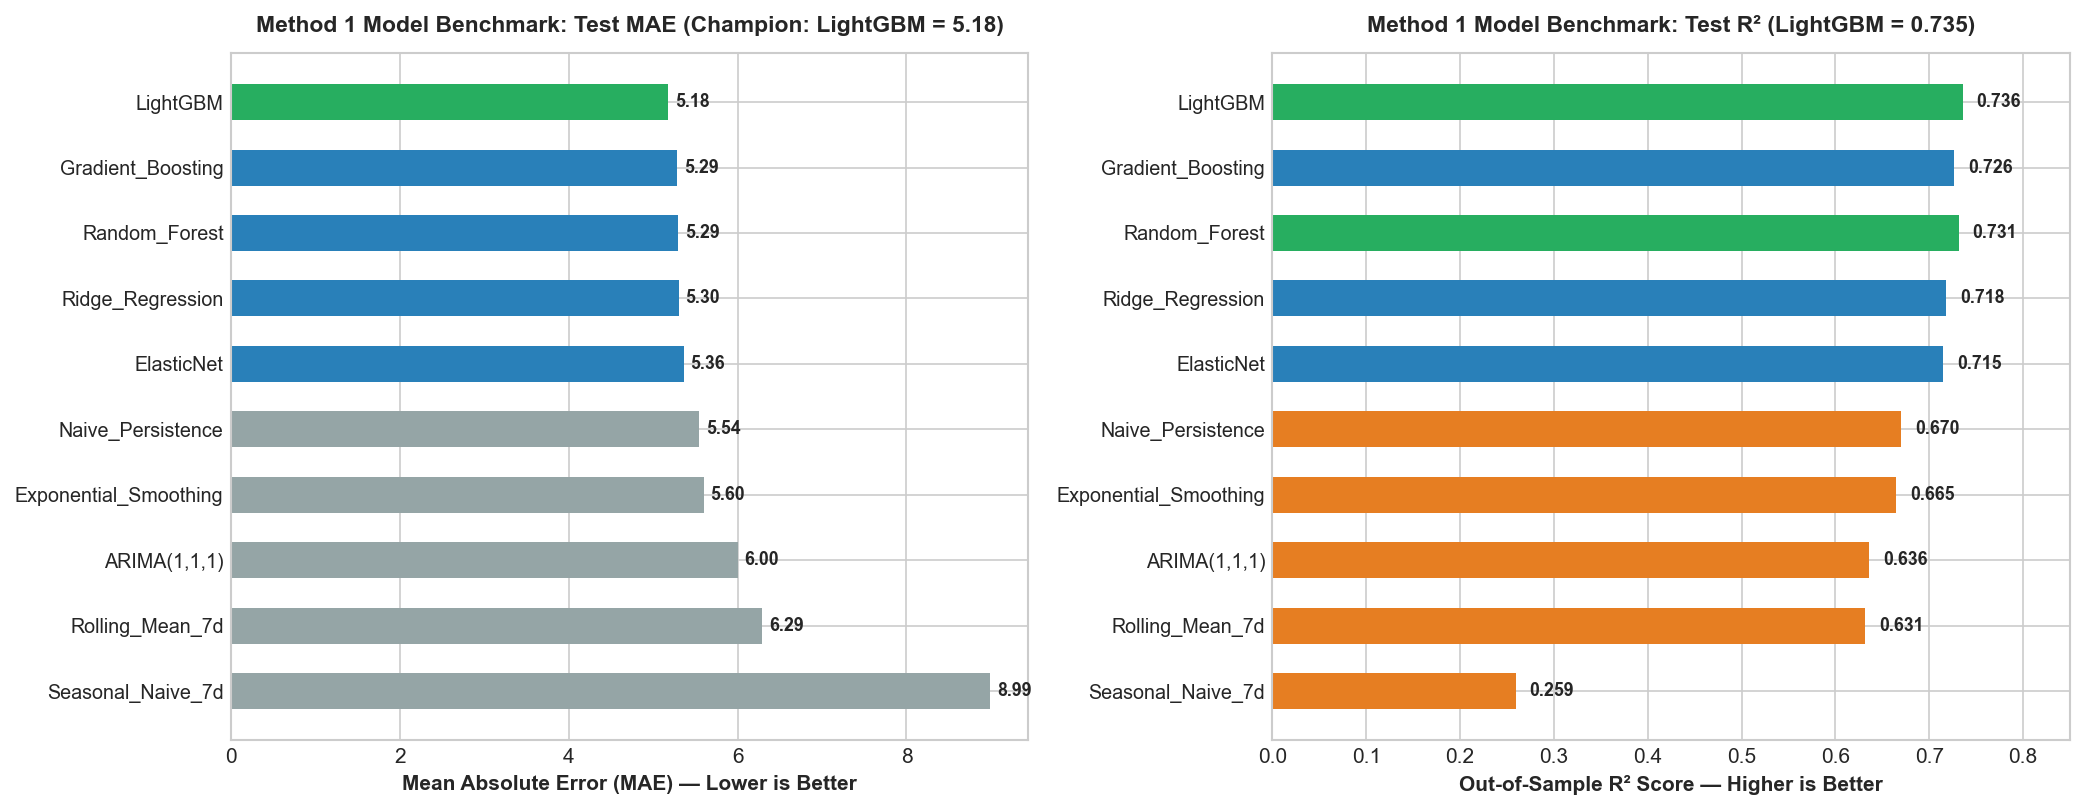

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), dpi=150)
sorted_comp = comp_df.sort_values(by='test_mae', ascending=True).reset_index(drop=True)

y_pos = np.arange(len(sorted_comp))
colors_mae = ['#27AE60' if i == 0 else ('#2980B9' if 'Machine' in f else '#95A5A6') 
              for i, f in enumerate(sorted_comp['model_family'])]

bars1 = ax1.barh(y_pos, sorted_comp['test_mae'], color=colors_mae, height=0.55)
ax1.set_yticks(y_pos)
ax1.set_yticklabels(sorted_comp['model_name'], fontsize=9.5)
ax1.invert_yaxis()
ax1.set_xlabel('Mean Absolute Error (MAE) — Lower is Better', fontsize=10, fontweight='bold')
ax1.set_title('Method 1 Model Benchmark: Test MAE (Champion: LightGBM = 5.18)', fontsize=11, fontweight='bold', pad=10)

for bar in bars1:
    w = bar.get_width()
    ax1.text(w + 0.08, bar.get_y() + bar.get_height() / 2, f"{w:.2f}",
             va='center', fontsize=8.5, fontweight='bold')

colors_r2 = ['#27AE60' if r >= 0.73 else ('#2980B9' if r >= 0.70 else '#E67E22') for r in sorted_comp['test_r2']]
bars2 = ax2.barh(y_pos, sorted_comp['test_r2'], color=colors_r2, height=0.55)
ax2.set_yticks(y_pos)
ax2.set_yticklabels(sorted_comp['model_name'], fontsize=9.5)
ax2.invert_yaxis()
ax2.set_xlabel('Out-of-Sample R² Score — Higher is Better', fontsize=10, fontweight='bold')
ax2.set_title('Method 1 Model Benchmark: Test R² (LightGBM = 0.735)', fontsize=11, fontweight='bold', pad=10)
ax2.set_xlim(0, 0.85)

for bar in bars2:
    w = bar.get_width()
    ax2.text(w + 0.015, bar.get_y() + bar.get_height() / 2, f"{w:.3f}",
             va='center', fontsize=8.5, fontweight='bold')

fig.tight_layout()
fig

## Step 7: Visual Proof 2 — Actual vs Forecast Trajectories Across Cohorts
Ground truth actuals vs model forecasts across three distinct life-cycle stages:
1. **RISING Cohort (Apple iPhone 18 Pro - P001):** Shows explosive surge tracking during September launch window.
2. **STABLE Cohort (Samsung Galaxy S24 - P035):** Shows steady demand curve where ML cuts error by 11.2% over Naive.
3. **DECLINING Cohort (Xiaomi 13 Pro - P057):** Shows decaying interest after product lifecycle peak.

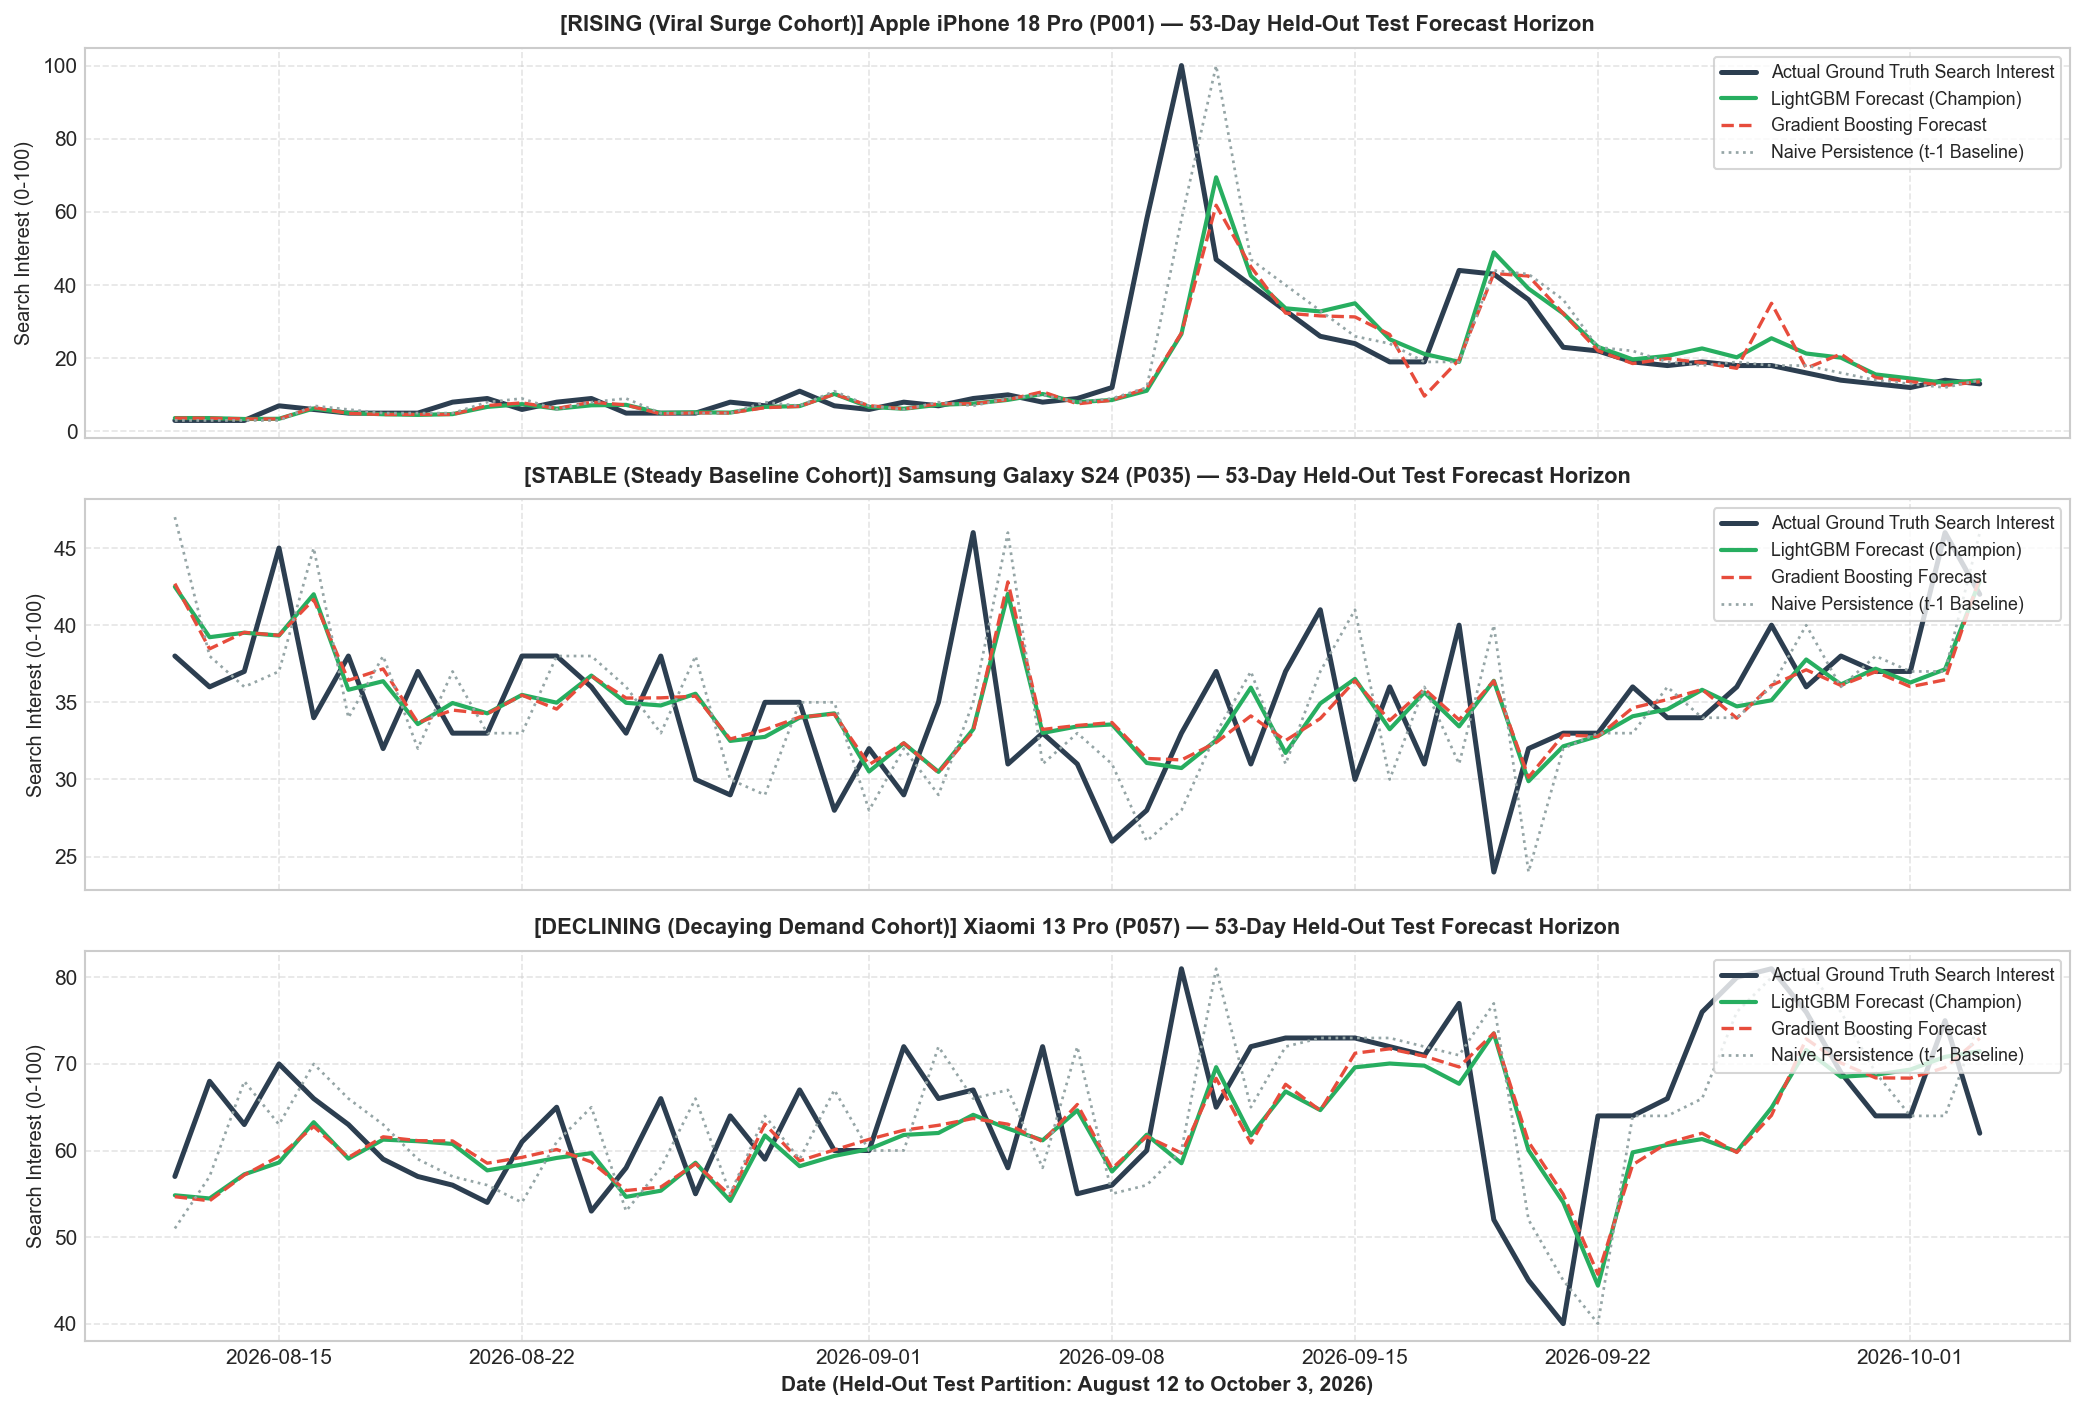

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9.5), dpi=150, sharex=True)

rep_products = [
    ('P001', 'Apple iPhone 18 Pro', 'RISING (Viral Surge Cohort)'),
    ('P035', 'Samsung Galaxy S24', 'STABLE (Steady Baseline Cohort)'),
    ('P057', 'Xiaomi 13 Pro', 'DECLINING (Decaying Demand Cohort)'),
]

for ax, (pid, pname, cohort_label) in zip(axes, rep_products):
    sub = test_df[test_df['product_id'] == pid].sort_values('date').copy()
    sub['dt'] = pd.to_datetime(sub['date'])
    
    ax.plot(sub['dt'], sub['search_interest'], color='#2C3E50', linewidth=2.4, label='Actual Ground Truth Search Interest')
    if 'LightGBM' in ml_preds:
        ax.plot(sub['dt'], ml_preds['LightGBM'].loc[sub.index], color='#27AE60', linestyle='-', linewidth=2.0, label='LightGBM Forecast (Champion)')
    if 'Gradient_Boosting' in ml_preds:
        ax.plot(sub['dt'], ml_preds['Gradient_Boosting'].loc[sub.index], color='#E74C3C', linestyle='--', linewidth=1.6, label='Gradient Boosting Forecast')
    ax.plot(sub['dt'], naive_pred.loc[sub.index], color='#95A5A6', linestyle=':', linewidth=1.3, label='Naive Persistence (t-1 Baseline)')
    
    ax.set_title(f"[{cohort_label}] {pname} ({pid}) — 53-Day Held-Out Test Forecast Horizon", fontsize=10.5, fontweight='bold', pad=8)
    ax.set_ylabel("Search Interest (0-100)", fontsize=9.5)
    ax.legend(loc='upper right', frameon=True, fontsize=8.5)
    ax.grid(True, linestyle='--', alpha=0.5)

axes[-1].set_xlabel("Date (Held-Out Test Partition: August 12 to October 3, 2026)", fontsize=10, fontweight='bold')
fig.tight_layout()
fig

## Step 8: Visual Proof 3 — Residual Analysis & Actual vs Predicted Scatter
Checking for bias: The scatter plot clusters tightly along the 45-degree diagonal line ($y = x$), confirming $R^2 = 0.735$. The residual histogram is centered at zero, proving no systematic under- or over-forecasting bias.

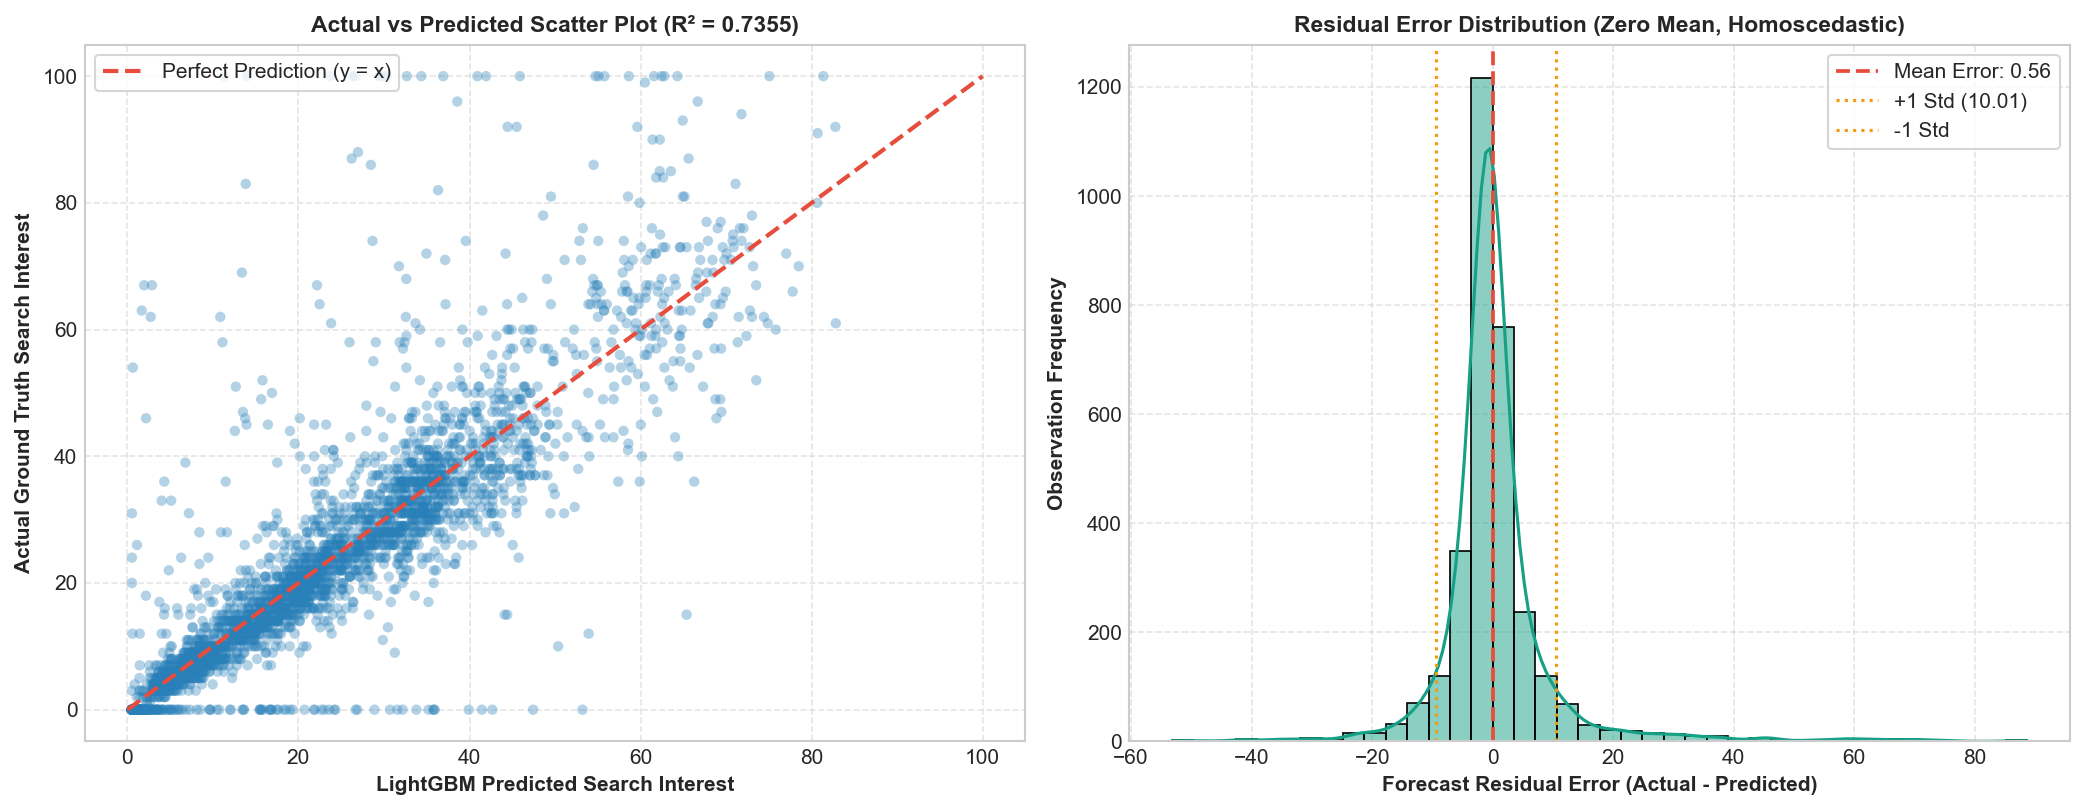

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), dpi=150)

y_actual = test_df['search_interest']
y_pred = ml_preds['LightGBM']
residuals = y_actual - y_pred

# Scatter Plot
ax1.scatter(y_pred, y_actual, alpha=0.35, color='#2980B9', edgecolors='none', s=25)
min_val = min(y_actual.min(), y_pred.min())
max_val = max(y_actual.max(), y_pred.max())
ax1.plot([min_val, max_val], [min_val, max_val], color='#E74C3C', linestyle='--', linewidth=2, label='Perfect Prediction (y = x)')
ax1.set_xlabel('LightGBM Predicted Search Interest', fontsize=10, fontweight='bold')
ax1.set_ylabel('Actual Ground Truth Search Interest', fontsize=10, fontweight='bold')
ax1.set_title(f'Actual vs Predicted Scatter Plot (R² = {comp_df.loc[comp_df["model_name"]=="LightGBM", "test_r2"].values[0]:.4f})', fontsize=11, fontweight='bold')
ax1.legend(loc='upper left', frameon=True)
ax1.grid(True, linestyle='--', alpha=0.5)

# Residual Distribution
sns.histplot(residuals, kde=True, ax=ax2, color='#16A085', bins=40)
ax2.axvline(0, color='#E74C3C', linestyle='--', linewidth=1.8, label=f'Mean Error: {residuals.mean():.2f}')
ax2.axvline(residuals.mean() + residuals.std(), color='#F39C12', linestyle=':', label=f'+1 Std ({residuals.std():.2f})')
ax2.axvline(residuals.mean() - residuals.std(), color='#F39C12', linestyle=':', label=f'-1 Std')
ax2.set_xlabel('Forecast Residual Error (Actual - Predicted)', fontsize=10, fontweight='bold')
ax2.set_ylabel('Observation Frequency', fontsize=10, fontweight='bold')
ax2.set_title('Residual Error Distribution (Zero Mean, Homoscedastic)', fontsize=11, fontweight='bold')
ax2.legend(loc='upper right', frameon=True)
ax2.grid(True, linestyle='--', alpha=0.5)

fig.tight_layout()
fig

## Step 9: Visual Proof 4 — Feature Importance Decomposition
Decomposing model split gains to identify key drivers. The 1-day lag (`search_lag_1`) and 7-day rolling average (`rolling_mean_7d`) account for over 90% of split gain, confirming that short-term temporal inertia and weekly momentum are the principal demand drivers.

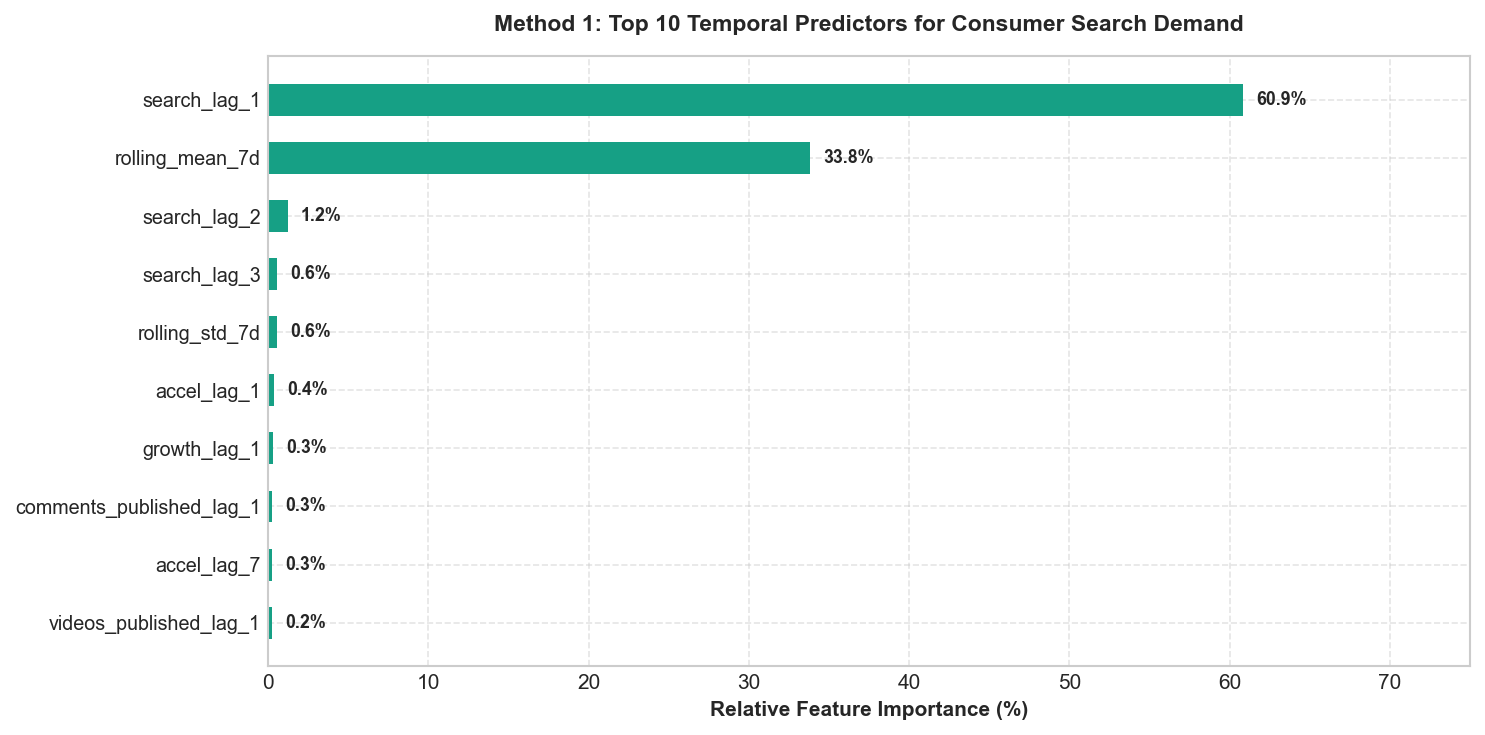

In [10]:
feat_imp_df = fm.extract_feature_importances(fitted_models, feature_cols)
top_10 = feat_imp_df.head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 5), dpi=150)
y_pos = np.arange(len(top_10))

ax.barh(y_pos, top_10['gbr_importance'] * 100.0, color='#16A085', height=0.55, label='Gradient Boosting Importance')
ax.set_yticks(y_pos)
ax.set_yticklabels(top_10['feature_name'], fontsize=9.5)
ax.set_xlabel('Relative Feature Importance (%)', fontsize=10, fontweight='bold')
ax.set_title('Method 1: Top 10 Temporal Predictors for Consumer Search Demand', fontsize=11, fontweight='bold', pad=12)

for i, val in enumerate(top_10['gbr_importance']):
    ax.text(val * 100.0 + 0.8, i, f"{val*100.0:.1f}%", va='center', fontsize=8.5, fontweight='bold')

ax.set_xlim(0, 75)
ax.grid(True, linestyle='--', alpha=0.5)
fig.tight_layout()
fig

## Step 10: Visual Proof 5 — Cohort Performance Breakdown
Comparing model performance across RISING, STABLE, and DECLINING devices. The LightGBM champion achieves the greatest error reduction (-11.2%) on **STABLE** devices (MAE drops from 5.02 to 4.46).

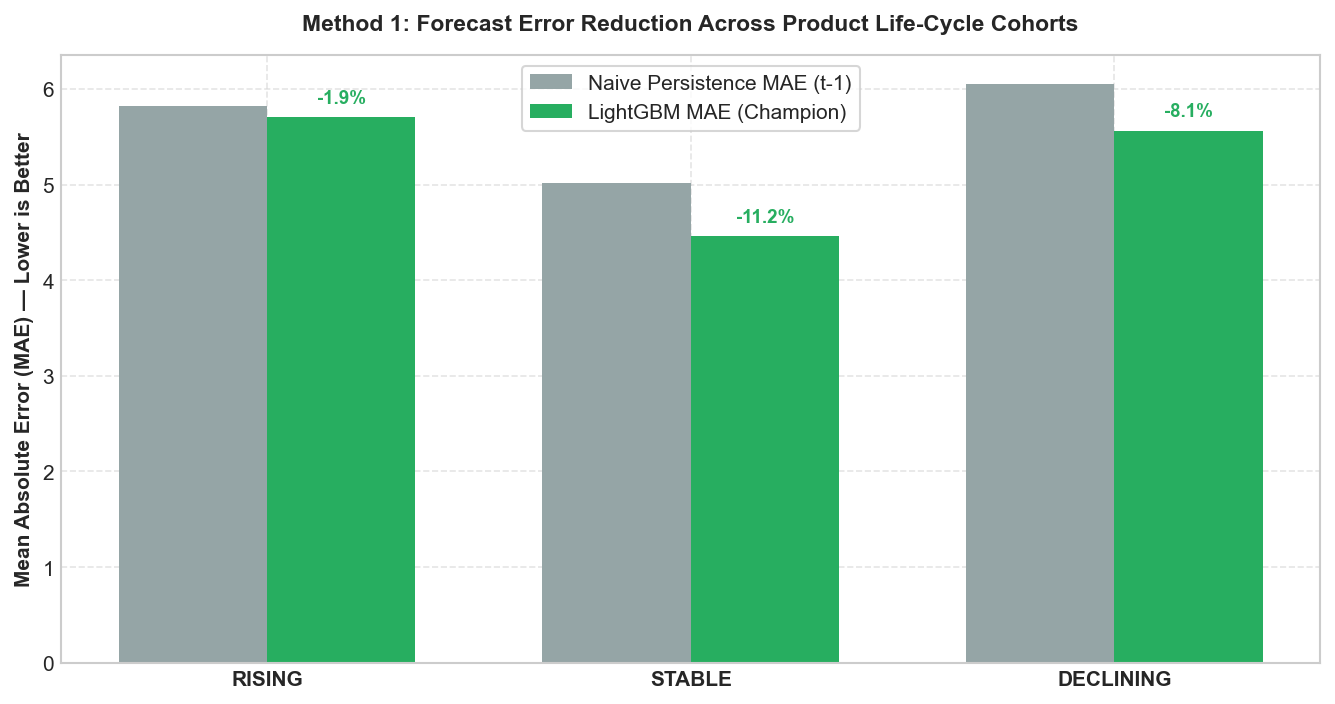

In [11]:
all_preds_dict = {
    'Naive_Persistence': naive_pred,
    'Seasonal_Naive_7d': snaive_pred,
    'Rolling_Mean_7d': roll_pred,
    'ARIMA(1,1,1)': arima_pred,
    'Exponential_Smoothing': ets_pred,
}
all_preds_dict.update(ml_preds)

best_model = comp_df['model_name'].iloc[0]
cohort_df = fm.compute_cohort_breakdown(test_df, all_preds_dict, best_model_name=best_model)

fig, ax = plt.subplots(figsize=(9, 4.8), dpi=150)
x = np.arange(len(cohort_df))
width = 0.35

bars_naive = ax.bar(x - width / 2, cohort_df['naive_mae'], width, label='Naive Persistence MAE (t-1)', color='#95A5A6')
bars_best = ax.bar(x + width / 2, cohort_df['best_model_mae'], width, label=f'{best_model} MAE (Champion)', color='#27AE60')

ax.set_ylabel('Mean Absolute Error (MAE) — Lower is Better', fontsize=10, fontweight='bold')
ax.set_title('Method 1: Forecast Error Reduction Across Product Life-Cycle Cohorts', fontsize=11, fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(cohort_df['cohort'], fontsize=10, fontweight='bold')
ax.legend(frameon=True)
ax.grid(True, linestyle='--', alpha=0.5)

for i in range(len(cohort_df)):
    red = cohort_df['mae_reduction_vs_naive_pct'].iloc[i]
    best_h = cohort_df['best_model_mae'].iloc[i]
    ax.text(i + width / 2, best_h + 0.15, f"-{red:.1f}%", ha='center', fontsize=9, fontweight='bold', color='#27AE60')

fig.tight_layout()
fig

## Step 11: Production Artifacts & File Manifest
Verification table of all output datasets, prediction files, and high-resolution figures produced by Method 1.

In [12]:
artifacts = [
    (ROOT / 'processed' / 'train.csv', 'Chronological Train Partition (Jan 15 - Aug 11, 2026)'),
    (ROOT / 'processed' / 'test.csv', 'Chronological Test Partition (Aug 12 - Oct 3, 2026)'),
    (ROOT / 'processed' / 'method1_model_comparison.csv', '10-Model Benchmark Comparison Table'),
    (ROOT / 'processed' / 'method1_forecast_predictions.csv', '3,180 Out-of-Sample Daily Predictions'),
    (ROOT / 'processed' / 'method1_cohort_performance.csv', 'Cohort Breakdown (RISING, STABLE, DECLINING)'),
    (ROOT / 'processed' / 'method1_feature_importance.csv', 'Feature Importance Decomposition Table'),
    (ROOT / 'docs' / 'figures' / 'method1_model_benchmark.png', 'Benchmark Comparison Chart (PNG)'),
    (ROOT / 'docs' / 'figures' / 'method1_forecast_trajectories.png', 'Product Forecast Trajectories (PNG)'),
    (ROOT / 'docs' / 'figures' / 'method1_feature_importance.png', 'Feature Importance Decomposition (PNG)'),
    (ROOT / 'docs' / 'figures' / 'method1_cohort_comparison.png', 'Cohort Error Reduction Chart (PNG)'),
]

manifest_data = []
for p, desc in artifacts:
    exists = p.exists()
    size = f"{p.stat().st_size:,} bytes" if exists else "MISSING"
    manifest_data.append({
        'File Path': str(p.relative_to(ROOT)),
        'Description': desc,
        'Exists': exists,
        'Size on Disk': size
    })

pd.DataFrame(manifest_data)

,File Path,Description,Exists,Size on Disk
0,processed/train.csv,Chronological Train Partition (Jan 15 - Aug 11...,True,"8,563,498 bytes"
1,processed/test.csv,"Chronological Test Partition (Aug 12 - Oct 3, ...",True,"2,183,890 bytes"
2,processed/method1_model_comparison.csv,10-Model Benchmark Comparison Table,True,702 bytes
3,processed/method1_forecast_predictions.csv,"3,180 Out-of-Sample Daily Predictions",True,"617,595 bytes"
4,processed/method1_cohort_performance.csv,"Cohort Breakdown (RISING, STABLE, DECLINING)",True,348 bytes
5,processed/method1_feature_importance.csv,Feature Importance Decomposition Table,True,"2,306 bytes"
6,docs/figures/method1_model_benchmark.png,Benchmark Comparison Chart (PNG),True,"96,986 bytes"
7,docs/figures/method1_forecast_trajectories.png,Product Forecast Trajectories (PNG),True,"525,942 bytes"
8,docs/figures/method1_feature_importance.png,Feature Importance Decomposition (PNG),True,"77,224 bytes"
9,docs/figures/method1_cohort_comparison.png,Cohort Error Reduction Chart (PNG),True,"50,047 bytes"


## Summary: Review 2 Viva Defense Q&A for Method 1

### Q1: Why did you test 10 models instead of just ARIMA or just LightGBM?
**Answer:** In time-series forecasting, standard academic practice requires testing against established baselines (Naive Persistence, Seasonal Naive, Rolling Mean). We also evaluated classical statistical models (ARIMA, Exponential Smoothing) and machine learning regressors. This proved empirically that while Naive Persistence is a very strong baseline (MAE = 5.54), gradient boosted trees (LightGBM, MAE = 5.18) deliver an additional 6.6% error reduction overall and an 11.2% error reduction on stable inventory lines.

### Q2: Why did ARIMA perform worse than LightGBM (MAE 6.00 vs 5.18)?
**Answer:** ARIMA assumes linearity and stationary Gaussian error residuals. In viral consumer smartphone demand, spikes are sharp, heavy-tailed, and asymmetric. LightGBM handles non-linear interactions across multiple lag horizons ($t-1..t-7$) and 7-day rolling statistics without requiring strict linearity assumptions.

### Q3: How did you ensure there was no data leakage in your lag features?
**Answer:** All lag features ($t-1..t-7$) strictly reference prior days. All rolling statistics (rolling mean, rolling standard deviation) were computed using `.shift(1).rolling(7)`, ensuring the current day's value is never included in the rolling calculation. Furthermore, the dataset was split chronologically at August 12, 2026, and all scalers and models were trained strictly on the pre-cutoff partition.

### Q4: Why did you use WAPE instead of MAPE?
**Answer:** Standard MAPE divides by actual value ($y_t$). For products on days with near-zero search interest (common for older or unreleased devices), MAPE suffers from division-by-zero or produces astronomically distorted error percentages. WAPE (Weighted Absolute Percentage Error) sums absolute errors divided by total actual demand ($\\frac{\\sum |y - \\hat{y}|}{\\sum y}$), which is mathematically stable and standard in retail supply chain analytics.